In [8]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [9]:
!pip install medmnist

In [10]:
import numpy as np
import medmnist
from medmnist import INFO, BloodMNIST

print("medmnist version:", medmnist.__version__)

info = INFO["bloodmnist"]
for key in ["task", "n_channels", "n_samples", "license"]:
    print(key, ":", info.get(key))
print(info["label"])

train = BloodMNIST(split="train", download=True)
val = BloodMNIST(split="val", download=True)
test = BloodMNIST(split="test", download=True)

print()
print("train / val / test:", len(train), len(val), len(test))
print("images:", train.imgs.shape, train.imgs.dtype)
print("labels:", train.labels.shape)

medmnist version: 3.0.2
task : multi-class
n_channels : 3
n_samples : {'train': 11959, 'val': 1712, 'test': 3421}
license : CC BY 4.0
{'0': 'basophil', '1': 'eosinophil', '2': 'erythroblast', '3': 'immature granulocytes(myelocytes, metamyelocytes and promyelocytes)', '4': 'lymphocyte', '5': 'monocyte', '6': 'neutrophil', '7': 'platelet'}

train / val / test: 11959 1712 3421
images: (11959, 28, 28, 3) uint8
labels: (11959, 1)


In [11]:
# Cell 3: class counts
import pandas as pd

names = {int(k): v.split("(")[0].strip() for k, v in info["label"].items()}

rows = {}
for split_name, ds in [("train", train), ("val", val), ("test", test)]:
    rows[split_name] = pd.Series(ds.labels.ravel()).value_counts().sort_index()

counts = pd.DataFrame(rows).rename(index=names)
counts["train %"] = (counts["train"] / counts["train"].sum() * 100).round(1)
counts["test %"] = (counts["test"] / counts["test"].sum() * 100).round(1)
print(counts)
print()

majority = counts["train"].idxmax()
share = counts.loc[majority, "test"] / counts["test"].sum() * 100
print("most common class in train:", majority)
print("accuracy of always predicting it on test:", round(share, 1), "%")
print()
print("pixel min/max:", train.imgs.min(), train.imgs.max())
print("mean per colour channel (R, G, B):", train.imgs.mean(axis=(0, 1, 2)).round(1))

                       train  val  test  train %  test %
basophil                 852  122   244      7.1     7.1
eosinophil              2181  312   624     18.2    18.2
erythroblast            1085  155   311      9.1     9.1
immature granulocytes   2026  290   579     16.9    16.9
lymphocyte               849  122   243      7.1     7.1
monocyte                 993  143   284      8.3     8.3
neutrophil              2330  333   666     19.5    19.5
platelet                1643  235   470     13.7    13.7

most common class in train: neutrophil
accuracy of always predicting it on test: 19.5 %

pixel min/max: 0 255
mean per colour channel (R, G, B): [202.6 168.2 177.5]


cell 4 started


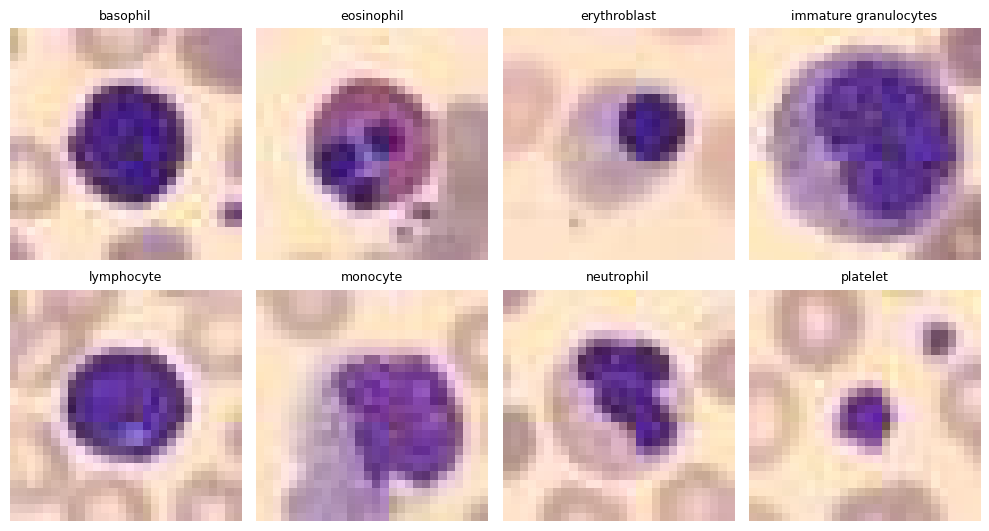

cell 4 finished


In [12]:

%matplotlib inline
import matplotlib.pyplot as plt
import os

os.makedirs("figures", exist_ok=True)
print("cell 4 started")

fig, axes = plt.subplots(2, 4, figsize=(10, 5.5))
for cls, ax in zip(range(8), axes.ravel()):
    idx = np.where(train.labels.ravel() == cls)[0][0]
    ax.imshow(train.imgs[idx])
    ax.set_title(names[cls], fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.savefig("figures/sample_images.png", dpi=150)
plt.show()

print("cell 4 finished")

In [13]:
# Cell 5: data prep and majority-class baseline, judged on the validation set
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score
import time

X_train = train.imgs.reshape(len(train), -1) / 255.0
y_train = train.labels.ravel()
X_val = val.imgs.reshape(len(val), -1) / 255.0
y_val = val.labels.ravel()
print("feature matrix:", X_train.shape)

def evaluate(name, y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred, average="macro")
    print(f"{name}: accuracy = {acc:.3f}, macro-F1 = {f1:.3f}")

maj_class = np.bincount(y_train).argmax()
evaluate("majority class", y_val, np.full(len(y_val), maj_class))

feature matrix: (11959, 2352)
majority class: accuracy = 0.195, macro-F1 = 0.041


In [14]:
# Cell 5b: logistic regression on raw pixels (timed)
t0 = time.time()
logreg = LogisticRegression(max_iter=100)
logreg.fit(X_train, y_train)
print(f"fit took {time.time() - t0:.0f} seconds")
evaluate("logistic regression (pixels)", y_val, logreg.predict(X_val))

fit took 18 seconds
logistic regression (pixels): accuracy = 0.810, macro-F1 = 0.782


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [15]:
# Cell 5c: random forest on raw pixels (timed)
t0 = time.time()
rf = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
print(f"fit took {time.time() - t0:.0f} seconds")
evaluate("random forest (pixels)", y_val, rf.predict(X_val))

fit took 25 seconds
random forest (pixels): accuracy = 0.849, macro-F1 = 0.824
